## Setup

In [1]:
# %%
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from ipywidgets import interact, IntSlider, fixed
import os
import cv2

In [2]:
image_path = 'v2_default.png'
# image_path = 'v2_white_background.png'
# image_path = 'v2_lid_on.png'
# image_path = 'v2_without_black.png'

def load_image(image_path):
    # Load and convert the image to RGB if not already in that mode
    image = Image.open(image_path).convert("RGB")
    return image
def display_image_with_pixel_value(image_path, x, y):
    # Load the image
    image = load_image(image_path)
    # Convert image to array for display purposes
    image_array = np.array(image)
    # Get the RGB value at the selected coordinates
    rgb_value = image.getpixel((x, y))
    # Create a copy of the image to draw the red dot
    draw = ImageDraw.Draw(image)
    dot_radius = 5
    draw.ellipse((x - dot_radius, y - dot_radius, x + dot_radius, y + dot_radius), fill='red', outline='red')
    # Display the image with the red dot
    plt.figure(figsize=(6,6))  # Optional: Set figure size
    plt.imshow(image)
    plt.axis('on')
    plt.title(f'RGB value at ({x}, {y}): {rgb_value}')
# Load the image and get dimensions
image = load_image(image_path)
width, height = image.size
# Create interactive sliders for x and y coordinates
interact(display_image_with_pixel_value,
         image_path=fixed(image_path),
         x=IntSlider(min=0, max=width-1, step=1, value=width//2),
         y=IntSlider(min=0, max=height-1, step=1, value=height//2))

interactive(children=(IntSlider(value=255, description='x', max=510), IntSlider(value=381, description='y', ma…

<function __main__.display_image_with_pixel_value(image_path, x, y)>

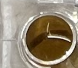

In [3]:
width, height = image.size

# Convert the image to RGB format
rgb_image = load_image(image_path).convert('RGB')

# Define the region (x1, y1, x2, y2)
# (x1, y1) is the top-left corner, (x2, y2) is the bottom-right corner
region = (0, 0, 78, 68)  # Example coordinates for the region

# Crop the selected region
cropped_region = rgb_image.crop(region)

ydiff = 100

region2 = (320, 125, 500, 275)
cropped_region2 = rgb_image.crop(region)
# Convert the cropped region to a NumPy array
region_np = np.array(cropped_region)

# Get the RGB values
# The shape of region_np will be (height, width, 3), where 3 represents the RGB channels
rgb_values = region_np.reshape(-1, 3)

# Print the RGB values
cropped_region

### Old Example

In [4]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# # Parameters for bilateral filter
# diameter = 5
# sigmaColor = 75
# sigmaSpace = 75

# # Load the image
# image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
# image = cv2.bilateralFilter(image, diameter, sigmaColor, sigmaSpace)
# image_rgb = cv2.imread(image_path)

# # Apply thresholding to isolate wells
# ret, thresh = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)

# # Find contours of the wells
# contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# # Helper function to get the centroid y-coordinate of a contour
# def get_contour_y(contour):
#     M = cv2.moments(contour)
#     if M["m00"] != 0:
#         return int(M["m01"] / M["m00"])  # Y-coordinate of the centroid
#     return 0

# # Function to calculate circularity
# def calculate_circularity(contour):
#     area = cv2.contourArea(contour)
#     perimeter = cv2.arcLength(contour, True)
#     if perimeter == 0:
#         return 0
#     return (4 * np.pi * area) / (perimeter**2)

# # Filter and sort contours
# contour_plot = []
# rgb_values = []

# # Minimum area to consider a contour valid
# min_area = 900

# # Circularity threshold for filtering
# min_circularity = 0.17  # Adjust as needed (closer to 1 means stricter filtering)

# # Iterate through each detected contour
# for contour in sorted(contours, key=get_contour_y):
#     area = cv2.contourArea(contour)
#     if area < min_area:
#         continue  # Skip small contours

#     circularity = calculate_circularity(contour)
#     if circularity < min_circularity:
#         continue  # Skip non-circular contours

#     contour_plot.append(contour)

#     # Create a mask for the current well
#     mask = np.zeros(image_rgb.shape[:2], dtype="uint8")
#     cv2.drawContours(mask, [contour], -1, 255, -1)

#     # Extract the ROI (well) using the mask
#     well_pixels = cv2.bitwise_and(image_rgb, image_rgb, mask=mask)
    
#     # Calculate the average BGR values
#     mean_val = cv2.mean(image_rgb, mask=mask)[:3]
#     rgb_values.append(mean_val[::-1])  # Reverse BGR output to RGB

# # Draw the filtered contours
# output_image = image_rgb.copy()
# cv2.drawContours(output_image, contour_plot, -1, (0, 0, 255), 2)
# output_image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)  # Convert to RGB for matplotlib

# # Display the results
# plt.figure(figsize=(12, 10))
# plt.imshow(output_image_rgb)
# plt.axis('off')  # Hide axis
# plt.title('Circular Contours with RGB Data Extraction')
# plt.show()


## Analysis

### Dynamic Example

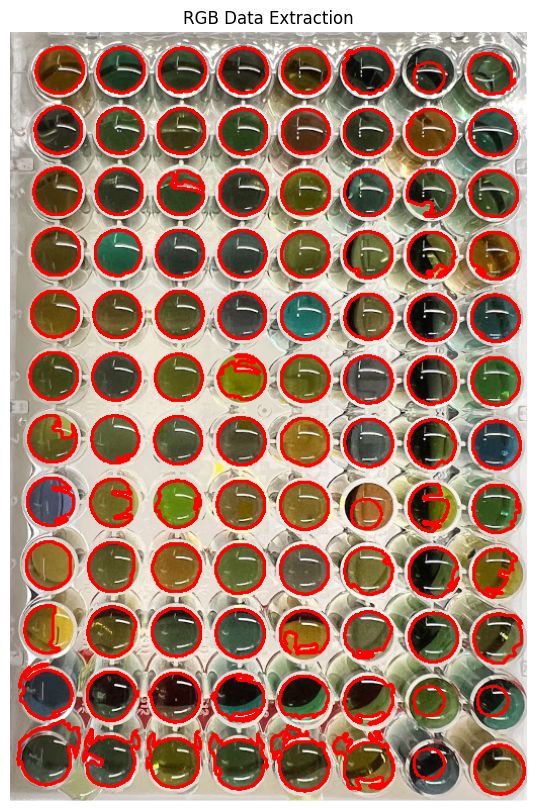

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Parameters for bilateral filter
diameter = 5
sigmaColor = 75
sigmaSpace = 75

# Load the image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
image = cv2.bilateralFilter(image, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

# Apply thresholding to isolate wells
ret, thresh = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)

# Find contours of the wells
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Helper function to get the centroid y-coordinate of a contour
def get_contour_centroid(contour):
    M = cv2.moments(contour)
    if M["m00"] != 0:
        return (int(M["m10"] / M["m00"]), int(M["m01"] / M["m00"]))
    return (0, 0)

# Function to calculate circularity
def calculate_circularity(contour):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    if perimeter == 0:
        return 0
    return (4 * np.pi * area) / (perimeter**2)

# Filter contours by area and circularity
contour_plot = []
rgb_values = []

# Minimum area to consider a contour valid
min_area = 900

# Circularity threshold for filtering
min_circularity = 0.17  # Adjust as needed (closer to 1 means stricter filtering)

for contour in contours:
    area = cv2.contourArea(contour)
    if area < min_area:
        continue  # Skip small contours

    circularity = calculate_circularity(contour)
    if circularity < min_circularity:
        continue  # Skip non-circular contours

    contour_plot.append(contour)

# Ensure 8x12 grid of contours
rows, cols = 12, 8
num_required_contours = rows * cols

# Find bounding box for the detected contours
if contour_plot:
    x, y, w, h = cv2.boundingRect(np.vstack(contour_plot))
else:
    x, y, w, h = 0, 0, image_rgb.shape[1], image_rgb.shape[0]

grid_w, grid_h = w / cols, h / rows

# Organize contours into a sorted grid
grid = [[None for _ in range(cols)] for _ in range(rows)]
for contour in contour_plot:
    centroid = get_contour_centroid(contour)
    grid_x = int((centroid[0] - x) / grid_w)
    grid_y = int((centroid[1] - y) / grid_h)
    if 0 <= grid_x < cols and 0 <= grid_y < rows:
        grid[grid_y][grid_x] = contour

# Fill empty grid cells with artificial contours and compute RGB
for row_idx, row in enumerate(grid):
    for col_idx, contour in enumerate(row):
        if contour is None:
            # Add artificial contours for empty cells
            grid_x = int(x + col_idx * grid_w + grid_w / 2)
            grid_y = int(y + row_idx * grid_h + grid_h / 2)
            radius = int(min(grid_w, grid_h) / 4)
            synthetic_contour = np.array(
                [[grid_x + radius * np.cos(theta), grid_y + radius * np.sin(theta)]
                 for theta in np.linspace(0, 2 * np.pi, 20)],
                dtype=np.int32
            )
            mask = np.zeros(image_rgb.shape[:2], dtype="uint8")
            cv2.circle(mask, (grid_x, grid_y), radius, 255, -1)
            mean_val = cv2.mean(image_rgb, mask=mask)[:3]
            rgb_values.append(mean_val[::-1])  # RGB from BGR
            grid[row_idx][col_idx] = synthetic_contour
        else:
            # Compute RGB for real contours
            mask = np.zeros(image_rgb.shape[:2], dtype="uint8")
            cv2.drawContours(mask, [contour], -1, 255, -1)
            mean_val = cv2.mean(image_rgb, mask=mask)[:3]
            rgb_values.append(mean_val[::-1])  # RGB from BGR

# Draw the final contours
output_image = image_rgb.copy()
for row in grid:
    for contour in row:
        cv2.drawContours(output_image, [contour], -1, (0, 0, 255), 2)

output_image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)  # Convert to RGB for matplotlib

# Display the results
plt.figure(figsize=(12, 10))
plt.imshow(output_image_rgb)
plt.axis('off')  # Hide axis
plt.title('RGB Data Extraction')
plt.show()

# Verify the top-left circle's RGB value
# print("Top-left RGB value:", rgb_values[0])


### Number of Contours

In [6]:
def count_total_contours(contours, rows, cols, min_area, min_circularity):
    """
    Count the number of detected and artificial contours.
    
    Args:
    - contours: List of detected contours.
    - rows: Number of desired rows in the grid.
    - cols: Number of desired columns in the grid.
    - min_area: Minimum area for a valid contour.
    - min_circularity: Minimum circularity for a valid contour.
    
    Returns:
    - total_contours: Total number of contours, including artificial ones.
    """
    # Filter valid contours based on area and circularity
    valid_contours = []
    for contour in contours:
        area = cv2.contourArea(contour)
        if area < min_area:
            continue

        perimeter = cv2.arcLength(contour, True)
        if perimeter == 0:
            continue

        circularity = (4 * np.pi * area) / (perimeter**2)
        if circularity < min_circularity:
            continue

        valid_contours.append(contour)
    
    # Calculate the required number of contours
    num_required_contours = rows * cols

    # Count artificial contours
    artificial_contours = max(0, num_required_contours - len(valid_contours))
    
    # Total contours
    total_contours = len(valid_contours) + artificial_contours
    return total_contours, len(valid_contours), artificial_contours

# Example Usage
if __name__ == "__main__":
    # Assume contours is generated from the main script
    rows, cols = 12, 8
    min_area = 900
    min_circularity = 0.17

    # Replace with actual detected contours from your main script
    detected_contours = contours  

    # Count the total contours
    total, valid, artificial = count_total_contours(detected_contours, rows, cols, min_area, min_circularity)

    # Print results
    print(f"Total contours: {total}")
    print(f"Valid detected contours: {valid}")
    print(f"Artificially added contours: {artificial}")

Total contours: 96
Valid detected contours: 91
Artificially added contours: 5


### Color Mapping

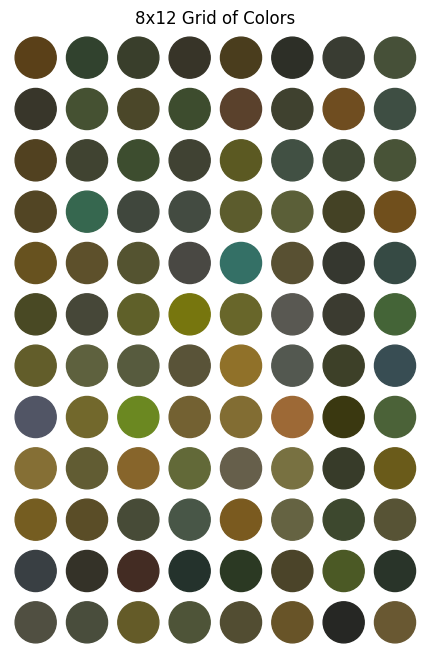

In [7]:
import matplotlib.pyplot as plt

# Number of rows and columns
rows, cols = 12, 8

# Create a figure and axis
fig, ax = plt.subplots(figsize=(12, 8))

# Ensure we have exactly rows * cols colors
if len(rgb_values) < rows * cols:
    # Fill with black if not enough colors
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

# Plot the grid of circles
for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        color = [val / 255 for val in rgb]  # Normalize RGB values to [0, 1] range
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, color=color)
        ax.add_patch(circle)

# Set the limits and adjust aspect ratio
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off')  # Remove axes

# Display the plot
plt.title('8x12 Grid of Colors')
plt.show()


In [11]:
print("RGB values:")
for idx, value in enumerate(formatted_rgb_values):
    print(f"{value},")
    # print(f"Row {idx // cols + 1}, Col {idx % cols + 1}: {value}")

RGB values:
(90, 64, 24),
(48, 65, 46),
(56, 62, 42),
(55, 52, 39),
(74, 61, 28),
(44, 47, 38),
(57, 59, 49),
(69, 79, 56),
(55, 54, 41),
(68, 81, 50),
(75, 70, 40),
(61, 75, 46),
(90, 65, 43),
(62, 65, 47),
(110, 77, 32),
(62, 78, 67),
(80, 64, 31),
(63, 66, 48),
(61, 76, 46),
(63, 66, 50),
(90, 88, 33),
(65, 79, 66),
(64, 72, 51),
(71, 82, 54),
(81, 69, 35),
(54, 102, 78),
(63, 71, 61),
(67, 75, 64),
(92, 92, 45),
(90, 94, 56),
(68, 66, 37),
(112, 78, 27),
(103, 82, 31),
(92, 79, 42),
(84, 83, 47),
(72, 72, 66),
(52, 112, 101),
(88, 79, 49),
(52, 55, 46),
(54, 73, 67),
(73, 73, 36),
(69, 71, 56),
(95, 96, 40),
(118, 118, 14),
(104, 101, 42),
(89, 88, 81),
(59, 59, 47),
(67, 100, 54),
(98, 92, 42),
(94, 97, 61),
(86, 91, 62),
(89, 82, 56),
(143, 112, 41),
(83, 87, 80),
(61, 63, 39),
(56, 76, 82),
(81, 85, 100),
(114, 103, 44),
(107, 135, 32),
(115, 97, 49),
(129, 108, 51),
(157, 105, 53),
(57, 56, 15),
(74, 98, 56),
(133, 110, 52),
(96, 91, 50),
(134, 100, 42),
(98, 104, 55),
(101, 94